# Лабораторная работа №2. Линейные модели регрессии и регуляризация

**Цель работы:** построить и сравнить линейные модели регрессии с различными видами регуляризации, освоить методы подбора гиперпараметров (Optuna, GridSearchCV, RandomizedSearchCV), реализовать метрики качества и линейную регрессию на SGD вручную.

**Данные:** `csv/winequality_finished.csv` (ЛР №1.2) — 6 497 образцов вина, целевой признак `quality`.

### Модели
| № | Модель | Подбор гиперпараметров |
|---|---|---|
| 1 | Линейная регрессия (МНК) | Optuna |
| 2 | Lasso ($L_1$) | Optuna |
| 3 | Ridge ($L_2$) | GridSearchCV |
| 4 | ElasticNet ($L_1 + L_2$) | RandomizedSearchCV |
| 5 | Полиномиальная регрессия + Ridge | Optuna |
| 6 | Собственная реализация: линейная регрессия + $L_2$, mini-batch SGD | — |

### Метрики
$$MSE = \frac{1}{n}\sum (y_i - \hat y_i)^2,\quad RMSE = \sqrt{MSE},\quad MAE = \frac{1}{n}\sum |y_i - \hat y_i|$$
$$MAPE = \frac{1}{n}\sum \left|\frac{y_i - \hat y_i}{y_i}\right|,\quad R^2 = 1 - \frac{\sum (y_i - \hat y_i)^2}{\sum (y_i - \bar y)^2}$$

> **Методика.** Все гиперпараметры подбираются по 5-кратной кросс-валидации **только на обучающей выборке**; масштабирование выполняется внутри `Pipeline`, чтобы исключить утечку данных. Тестовая выборка используется один раз — для финальной оценки.

## 1. Импорт библиотек и настройки

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
from scipy.stats import loguniform, uniform

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import (mean_squared_error, mean_absolute_error, root_mean_squared_error,
                             mean_absolute_percentage_error, r2_score)

optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 2. Вспомогательные функции: метрики и визуализация

Метрики реализованы вручную на NumPy и сверяются с реализациями `sklearn`.

In [2]:
def manual_metrics(y_true, y_pred):
    # Ручной расчёт метрик регрессии
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    err = y_true - y_pred
    mse = np.mean(err ** 2)
    return {
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'MAE': np.mean(np.abs(err)),
        'MAPE': np.mean(np.abs(err / y_true)),
        'R2': 1 - np.sum(err ** 2) / np.sum((y_true - y_true.mean()) ** 2),
    }


def sklearn_metrics(y_true, y_pred):
    return {
        'MSE': mean_squared_error(y_true, y_pred),
        'RMSE': root_mean_squared_error(y_true, y_pred),
        'MAE': mean_absolute_error(y_true, y_pred),
        'MAPE': mean_absolute_percentage_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred),
    }


results = {}  # итоговые метрики всех моделей


def evaluate(name, y_true, y_pred):
    # Сравнение библиотечных и ручных метрик + сохранение результата
    lib, man = sklearn_metrics(y_true, y_pred), manual_metrics(y_true, y_pred)
    results[name] = lib
    table = pd.DataFrame({'sklearn': lib, 'вручную': man})
    table['совпадают'] = np.isclose(table['sklearn'], table['вручную'])
    print(f'=== {name} ===')
    display(table.round(5))


def plot_actual_vs_predicted(y_true, y_pred, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    jitter = np.random.default_rng(RANDOM_STATE).uniform(-0.2, 0.2, len(y_true))
    axes[0].scatter(np.asarray(y_true) + jitter, y_pred, alpha=0.3, s=12)
    lims = [2.5, 9.5]
    axes[0].plot(lims, lims, 'r--', label='Идеальный прогноз')
    axes[0].set_xlabel('Истинное значение (с jitter)')
    axes[0].set_ylabel('Предсказание')
    axes[0].set_title(f'{title}: факт vs прогноз')
    axes[0].legend()

    residuals = np.asarray(y_true) - np.asarray(y_pred)
    sns.histplot(residuals, bins=40, kde=True, ax=axes[1])
    axes[1].axvline(0, color='red', linestyle='--')
    axes[1].set_title(f'{title}: распределение остатков')
    axes[1].set_xlabel('Остаток (y - ŷ)')
    plt.tight_layout()
    plt.show()

## 3. Загрузка данных и разбиение на выборки

In [3]:
data = pd.read_csv('csv/winequality_finished.csv', sep=';')
X = data.drop(columns=['quality'])
y = data['quality']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y.clip(4, 8)
)
print(f'Обучающая выборка: {X_train.shape}, тестовая: {X_test.shape}')

Обучающая выборка: (4872, 12), тестовая: (1625, 12)


Разбиение стратифицировано по `quality` (редкие оценки 3 и 9 объединены с соседними), чтобы распределение целевой переменной в обеих выборках совпадало.

## 4. Линейная регрессия (МНК) + Optuna
Единственный гиперпараметр — наличие свободного члена `fit_intercept` (`True` или `False`). Используем `GridSampler` с полным перебором из 2 испытаний (`n_trials=2`); оптимизируется MSE на 5-кратной кросс-валидации.

Лучшие параметры: {'fit_intercept': True} | CV MSE = 0.5403
=== LinearRegression ===


,sklearn,вручную,совпадают
MSE,0.53776,0.53776,True
RMSE,0.73332,0.73332,True
MAE,0.57103,0.57103,True
MAPE,0.10227,0.10227,True
R2,0.29972,0.29972,True


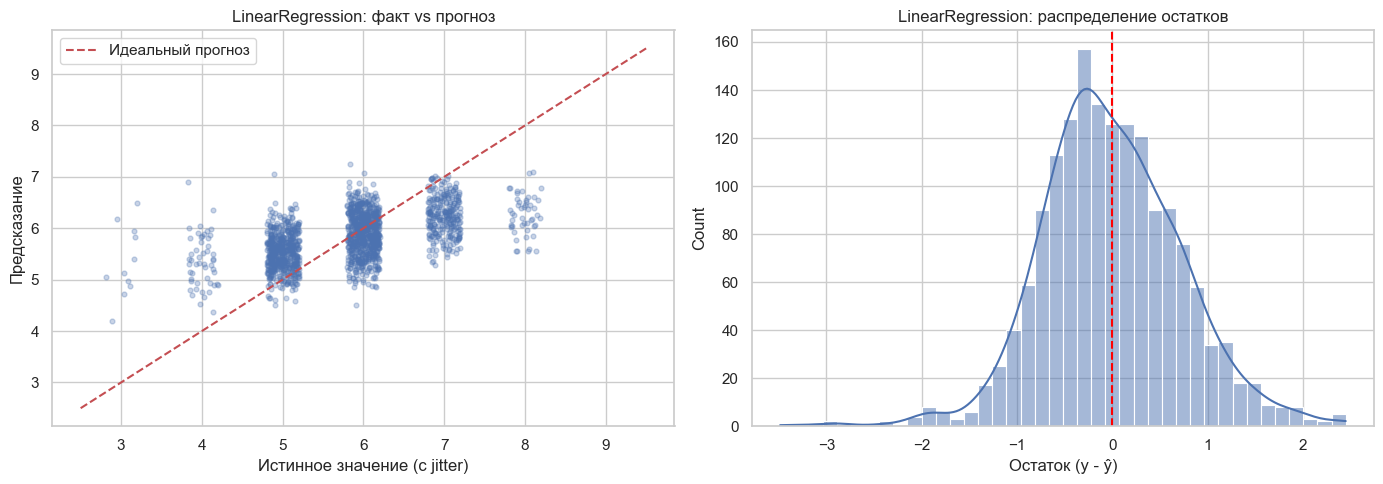

In [4]:
def make_pipe(model):
    return Pipeline([('scaler', StandardScaler()), ('model', model)])


def cv_mse(pipe):
    return -cross_val_score(pipe, X_train, y_train, cv=cv, scoring='neg_mean_squared_error').mean()


def objective_linear(trial):
    fit_intercept = trial.suggest_categorical('fit_intercept', [True, False])
    return cv_mse(make_pipe(LinearRegression(fit_intercept=fit_intercept)))


study_lr = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.GridSampler({'fit_intercept': [True, False]}),
)
study_lr.optimize(objective_linear, n_trials=2)
print('Лучшие параметры:', study_lr.best_params, '| CV MSE =', round(study_lr.best_value, 4))

lr_model = make_pipe(LinearRegression(**study_lr.best_params)).fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)
evaluate('LinearRegression', y_test, lr_pred)
plot_actual_vs_predicted(y_test, lr_pred, 'LinearRegression')

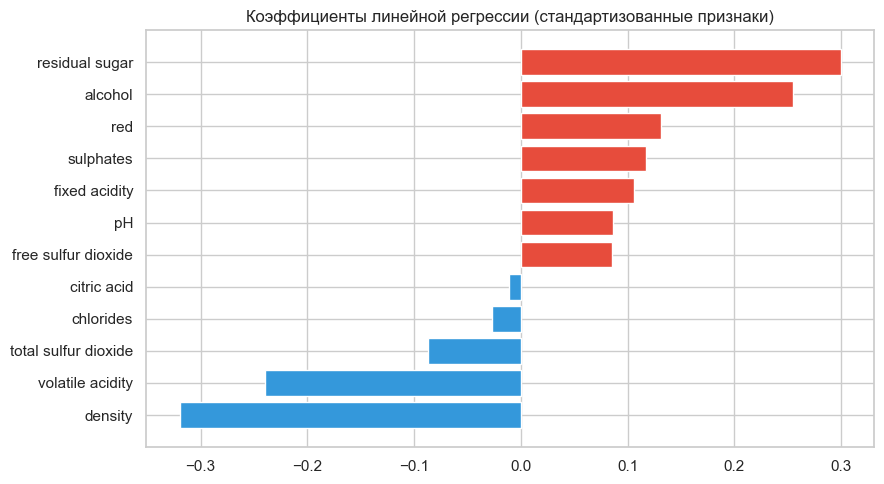

In [5]:
coefs = pd.Series(lr_model.named_steps['model'].coef_, index=X.columns).sort_values()
plt.figure(figsize=(9, 5))
plt.barh(coefs.index, coefs.values, color=['#e74c3c' if c > 0 else '#3498db' for c in coefs])
plt.title('Коэффициенты линейной регрессии (стандартизованные признаки)')
plt.tight_layout()
plt.show()

Без свободного члена (`fit_intercept=False`) модель вынуждена проходить через начало координат и даёт MSE ≈ 35, поэтому Optuna закономерно выбирает `fit_intercept=True`. Наибольший вклад вносят `alcohol`, `residual sugar` (+) и `density`, `volatile acidity` (−); большие по модулю коэффициенты при `density` и `residual sugar` — следствие их мультиколлинеарности.

## 5. Lasso ($L_1$-регуляризация) + Optuna
$$L(w) = \frac{1}{2n}\|y - Xw\|^2 + \alpha\|w\|_1$$

Лучшие параметры: {'alpha': 0.0005701256861337166} | CV MSE = 0.5402
=== Lasso (L1) ===


,sklearn,вручную,совпадают
MSE,0.53787,0.53787,True
RMSE,0.73340,0.73340,True
MAE,0.57113,0.57113,True
MAPE,0.10230,0.10230,True
R2,0.29958,0.29958,True


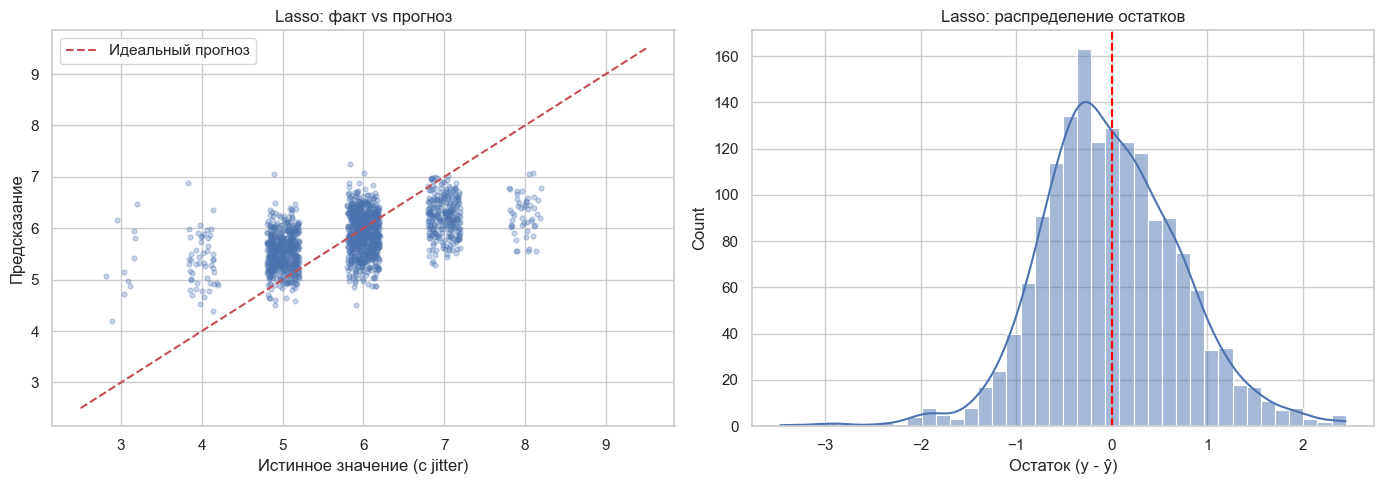

In [6]:
def objective_lasso(trial):
    alpha = trial.suggest_float('alpha', 1e-5, 1.0, log=True)
    return cv_mse(make_pipe(Lasso(alpha=alpha, max_iter=20000, random_state=RANDOM_STATE)))


study_lasso = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_lasso.optimize(objective_lasso, n_trials=40)
print('Лучшие параметры:', study_lasso.best_params, '| CV MSE =', round(study_lasso.best_value, 4))

lasso_model = make_pipe(Lasso(**study_lasso.best_params, max_iter=20000, random_state=RANDOM_STATE)).fit(X_train, y_train)
lasso_pred = lasso_model.predict(X_test)
evaluate('Lasso (L1)', y_test, lasso_pred)
plot_actual_vs_predicted(y_test, lasso_pred, 'Lasso')

Посмотрим, как $L_1$-регуляризация зануляет коэффициенты при увеличении $\alpha$ (путь регуляризации):

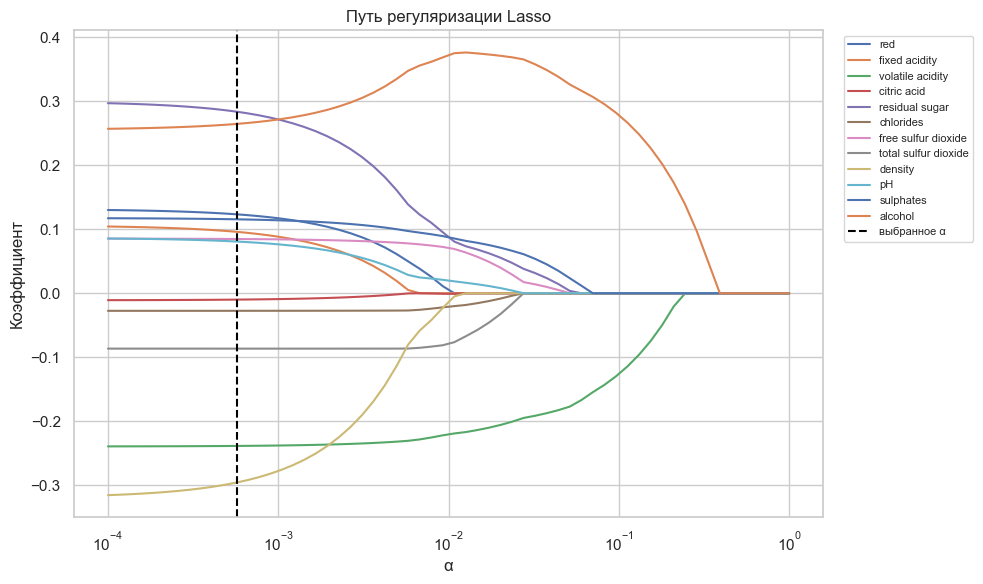

In [7]:
X_train_scaled = StandardScaler().fit_transform(X_train)
alphas = np.logspace(-4, 0, 60)
paths = np.array([Lasso(alpha=a, max_iter=20000).fit(X_train_scaled, y_train).coef_ for a in alphas])

plt.figure(figsize=(10, 6))
for i, col in enumerate(X.columns):
    plt.plot(alphas, paths[:, i], label=col)
plt.axvline(study_lasso.best_params['alpha'], color='black', linestyle='--', label='выбранное α')
plt.xscale('log')
plt.xlabel('α')
plt.ylabel('Коэффициент')
plt.title('Путь регуляризации Lasso')
plt.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 6. Ridge ($L_2$-регуляризация) + GridSearchCV
$$L(w) = \|y - Xw\|^2 + \alpha\|w\|_2^2$$

Лучшие параметры: {'model__alpha': np.float64(17.78279410038923)} | CV MSE = 0.5401
=== Ridge (L2) ===


,sklearn,вручную,совпадают
MSE,0.53793,0.53793,True
RMSE,0.73343,0.73343,True
MAE,0.57113,0.57113,True
MAPE,0.10230,0.10230,True
R2,0.29950,0.29950,True


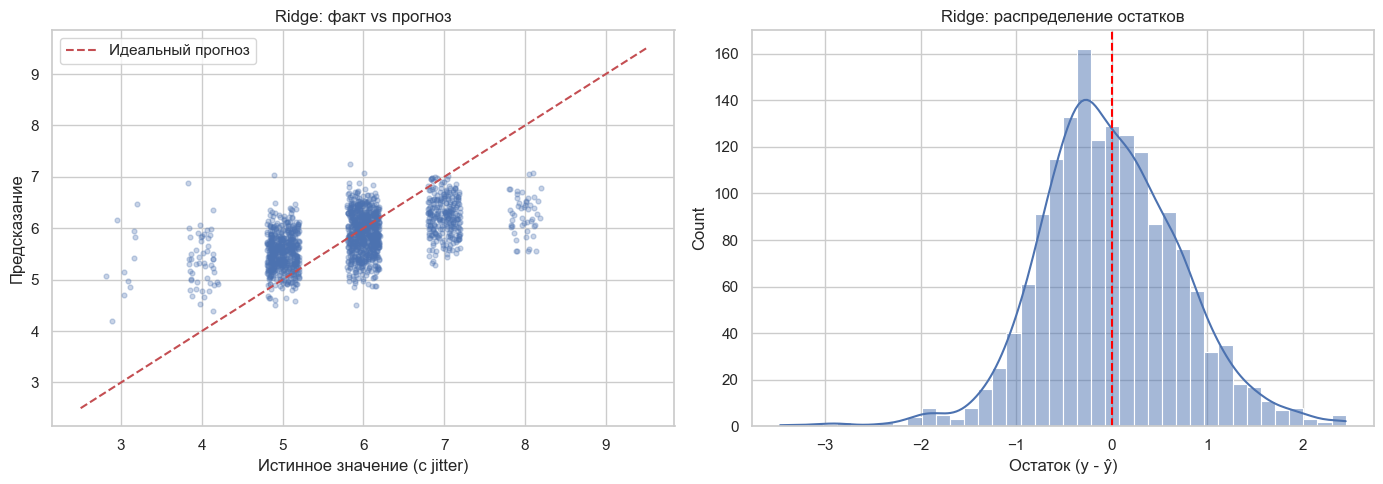

In [8]:
ridge_search = GridSearchCV(
    make_pipe(Ridge()),
    param_grid={'model__alpha': np.logspace(-3, 3, 25)},
    scoring='neg_mean_squared_error', cv=cv, n_jobs=-1,
)
ridge_search.fit(X_train, y_train)
print('Лучшие параметры:', ridge_search.best_params_, '| CV MSE =', round(-ridge_search.best_score_, 4))

ridge_pred = ridge_search.predict(X_test)
evaluate('Ridge (L2)', y_test, ridge_pred)
plot_actual_vs_predicted(y_test, ridge_pred, 'Ridge')

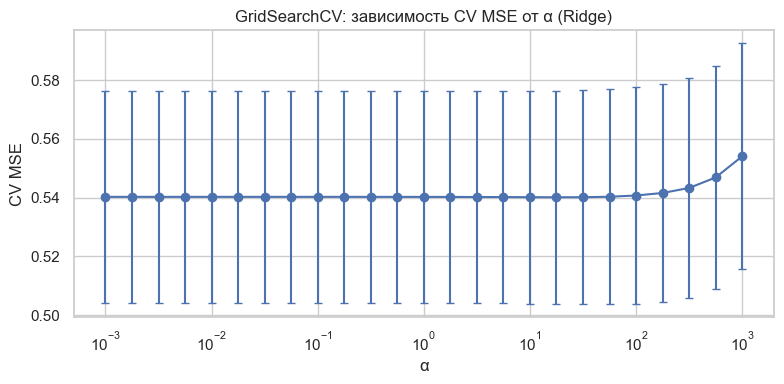

In [9]:
cv_res = pd.DataFrame(ridge_search.cv_results_)
plt.figure(figsize=(8, 4))
plt.errorbar(cv_res['param_model__alpha'].astype(float), -cv_res['mean_test_score'],
             yerr=cv_res['std_test_score'], marker='o', capsize=3)
plt.xscale('log')
plt.xlabel('α')
plt.ylabel('CV MSE')
plt.title('GridSearchCV: зависимость CV MSE от α (Ridge)')
plt.tight_layout()
plt.show()

## 7. ElasticNet ($L_1 + L_2$) + RandomizedSearchCV
$$L(w) = \frac{1}{2n}\|y - Xw\|^2 + \alpha\rho\|w\|_1 + \frac{\alpha(1-\rho)}{2}\|w\|_2^2$$
где $\rho$ = `l1_ratio`.

Лучшие параметры: {'model__alpha': np.float64(0.00144), 'model__l1_ratio': np.float64(0.29123)} | CV MSE = 0.5402
=== ElasticNet ===


,sklearn,вручную,совпадают
MSE,0.53789,0.53789,True
RMSE,0.73341,0.73341,True
MAE,0.57113,0.57113,True
MAPE,0.10230,0.10230,True
R2,0.29955,0.29955,True


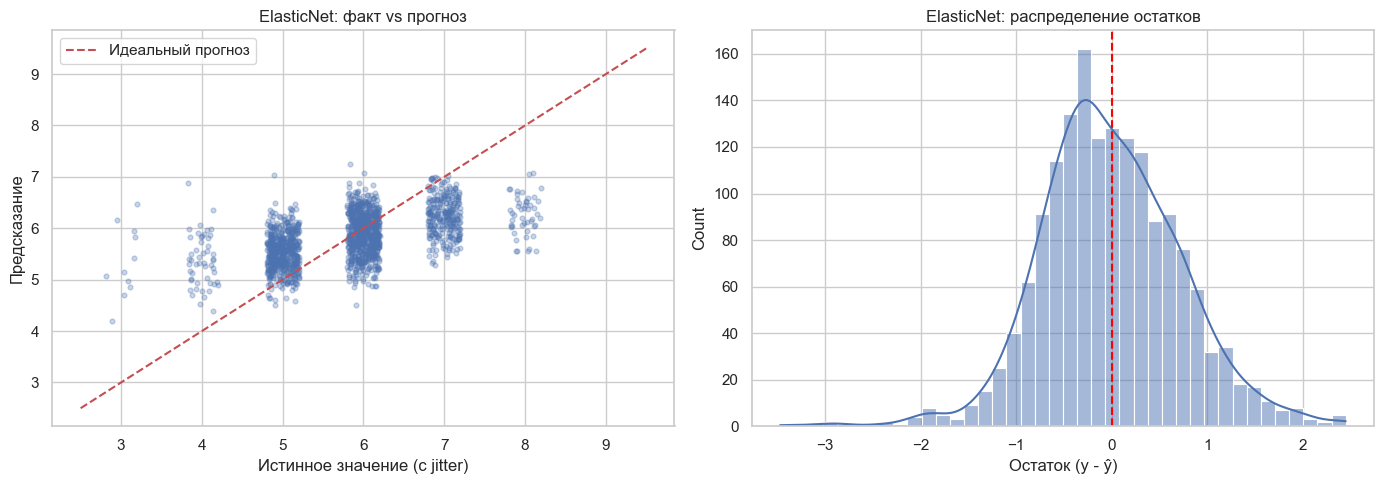

In [10]:
enet_search = RandomizedSearchCV(
    make_pipe(ElasticNet(max_iter=20000, random_state=RANDOM_STATE)),
    param_distributions={'model__alpha': loguniform(1e-5, 1.0), 'model__l1_ratio': uniform(0, 1)},
    n_iter=50, scoring='neg_mean_squared_error', cv=cv, n_jobs=-1, random_state=RANDOM_STATE,
)
enet_search.fit(X_train, y_train)
print('Лучшие параметры:', {k: round(v, 5) for k, v in enet_search.best_params_.items()},
      '| CV MSE =', round(-enet_search.best_score_, 4))

enet_pred = enet_search.predict(X_test)
evaluate('ElasticNet', y_test, enet_pred)
plot_actual_vs_predicted(y_test, enet_pred, 'ElasticNet')

## 8. Полиномиальная регрессия + Optuna
Добавляем полиномиальные признаки степени 2–3 (попарные произведения и квадраты). Число признаков резко растёт (12 → 90 при степени 2, → 454 при степени 3), поэтому без регуляризации модель переобучается. Используем `PolynomialFeatures` + `Ridge`, подбирая степень и $\alpha$ по кросс-валидации.

Лучшие параметры: {'degree': 2, 'alpha': 306.4944636160102} | CV MSE = 0.508
=== Polynomial + Ridge ===


,sklearn,вручную,совпадают
MSE,0.50509,0.50509,True
RMSE,0.71070,0.71070,True
MAE,0.55750,0.55750,True
MAPE,0.09983,0.09983,True
R2,0.34226,0.34226,True


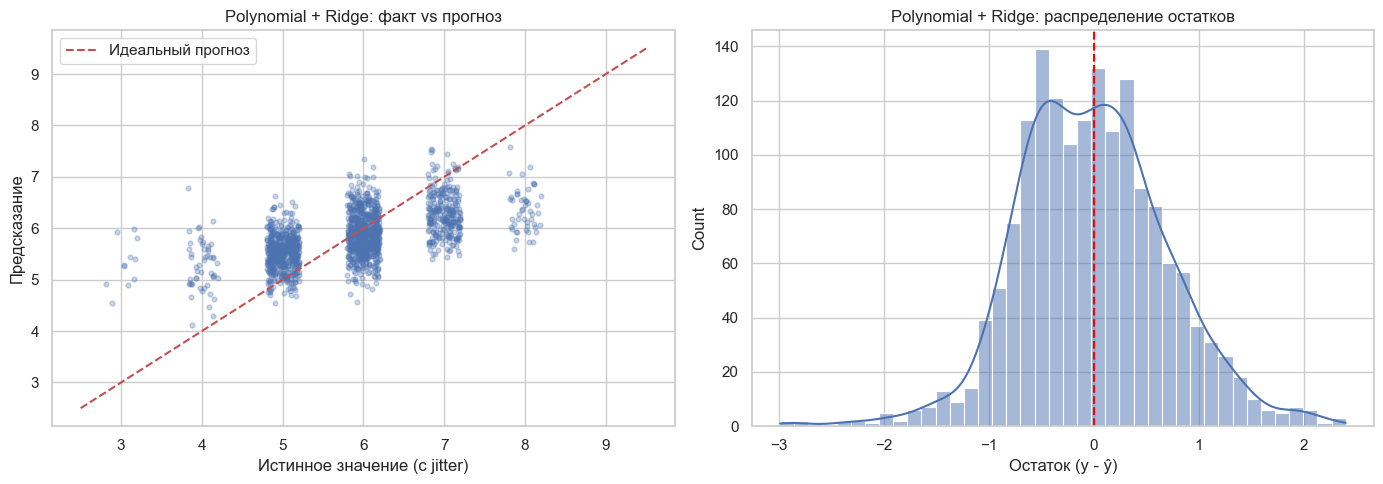

In [11]:
def make_poly_pipe(degree, alpha):
    return Pipeline([
        ('scaler', StandardScaler()),
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('model', Ridge(alpha=alpha)),
    ])


def objective_poly(trial):
    degree = trial.suggest_int('degree', 2, 3)
    alpha = trial.suggest_float('alpha', 1e-2, 1e4, log=True)
    return cv_mse(make_poly_pipe(degree, alpha))


study_poly = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_poly.optimize(objective_poly, n_trials=30)
print('Лучшие параметры:', study_poly.best_params, '| CV MSE =', round(study_poly.best_value, 4))

poly_model = make_poly_pipe(**study_poly.best_params).fit(X_train, y_train)
poly_pred = poly_model.predict(X_test)
evaluate('Polynomial + Ridge', y_test, poly_pred)
plot_actual_vs_predicted(y_test, poly_pred, 'Polynomial + Ridge')

Для сравнения — полиномиальная регрессия **без** регуляризации (так было сделано в исходной версии работы):

In [12]:
for degree in [2, 3]:
    pipe = Pipeline([('scaler', StandardScaler()),
                     ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
                     ('model', LinearRegression())]).fit(X_train, y_train)
    print(f'degree={degree}: train MSE = {mean_squared_error(y_train, pipe.predict(X_train)):.4f}, '
          f'test MSE = {mean_squared_error(y_test, pipe.predict(X_test)):.4f}')

degree=2: train MSE = 0.4745, test MSE = 0.5013
degree=3: train MSE = 0.3988, test MSE = 0.6275


Без регуляризации при степени 3 ошибка на обучении падает, а на тесте резко растёт — классическое переобучение. Подбор гиперпараметров по ошибке на обучающей выборке (как было в исходной версии) всегда выбирает наиболее сложную модель, поэтому кросс-валидация обязательна.

## 9. Собственная реализация: линейная регрессия с $L_2$-регуляризацией (mini-batch SGD)
Функция потерь и градиенты:
$$L(w, b) = \frac{1}{m}\sum_{i=1}^{m}(x_i^T w + b - y_i)^2 + \lambda\|w\|^2$$
$$\nabla_w L = \frac{2}{m}X^T(Xw + b - y) + 2\lambda w,\qquad \nabla_b L = \frac{2}{m}\sum (x_i^T w + b - y_i)$$
Класс совместим с API `scikit-learn` (`fit` / `predict`), поэтому его можно встраивать в `Pipeline`.

In [13]:
class LinearRegressionSGD(BaseEstimator, RegressorMixin):
    # Линейная регрессия с L2-регуляризацией, обучаемая мини-батчевым SGD

    def __init__(self, learning_rate=0.01, batch_size=32, n_epochs=200, lambda_l2=0.001, random_state=42):
        self.learning_rate = learning_rate
        self.batch_size = batch_size
        self.n_epochs = n_epochs
        self.lambda_l2 = lambda_l2
        self.random_state = random_state

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        n_samples, n_features = X.shape
        rng = np.random.RandomState(self.random_state)

        self.coef_ = rng.randn(n_features) * 0.01
        self.intercept_ = 0.0
        self.loss_history_ = []

        for _ in range(self.n_epochs):
            idx = rng.permutation(n_samples)
            for start in range(0, n_samples, self.batch_size):
                batch = idx[start:start + self.batch_size]
                Xb, yb = X[batch], y[batch]
                error = Xb @ self.coef_ + self.intercept_ - yb

                grad_w = 2 / len(batch) * Xb.T @ error + 2 * self.lambda_l2 * self.coef_
                grad_b = 2 / len(batch) * error.sum()

                self.coef_ -= self.learning_rate * grad_w
                self.intercept_ -= self.learning_rate * grad_b

            full_error = X @ self.coef_ + self.intercept_ - y
            self.loss_history_.append(np.mean(full_error ** 2) + self.lambda_l2 * np.sum(self.coef_ ** 2))
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_

=== LinearRegressionSGD (своя, L2) ===


,sklearn,вручную,совпадают
MSE,0.53789,0.53789,True
RMSE,0.73341,0.73341,True
MAE,0.57131,0.57131,True
MAPE,0.10243,0.10243,True
R2,0.29956,0.29956,True


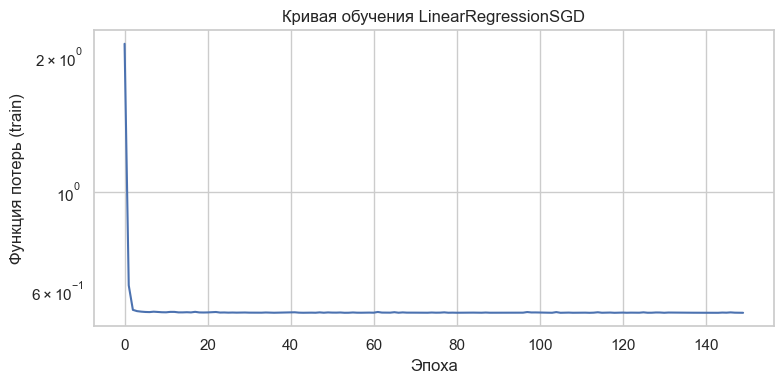

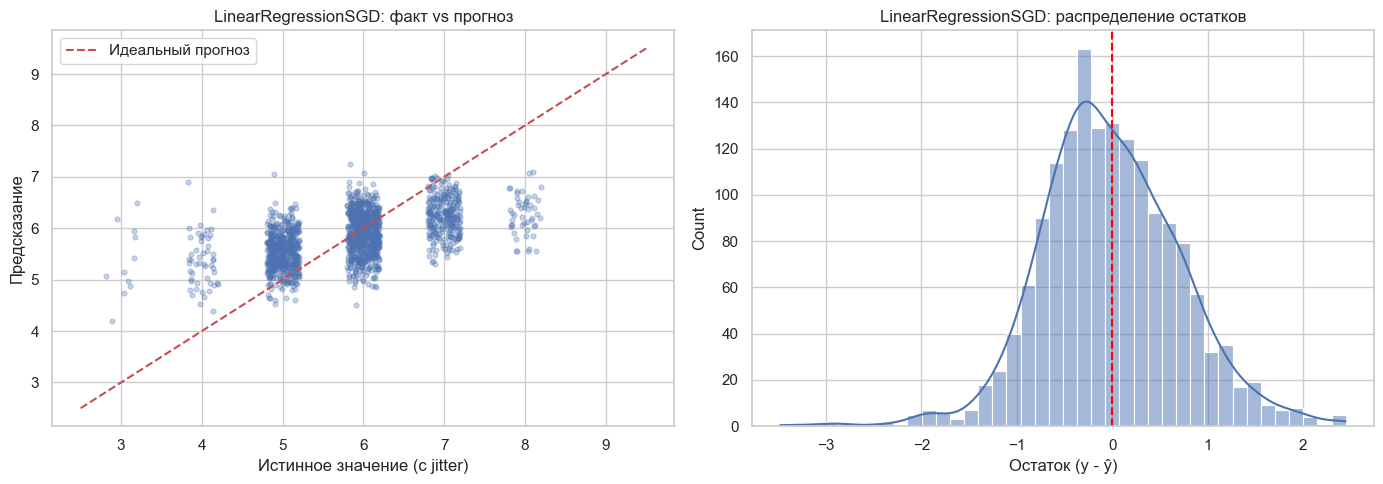

In [14]:
sgd_model = make_pipe(LinearRegressionSGD(learning_rate=0.005, batch_size=32, n_epochs=150, lambda_l2=0.001))
sgd_model.fit(X_train, y_train)
sgd_pred = sgd_model.predict(X_test)
evaluate('LinearRegressionSGD (своя, L2)', y_test, sgd_pred)

plt.figure(figsize=(8, 4))
plt.plot(sgd_model.named_steps['model'].loss_history_)
plt.yscale('log')
plt.xlabel('Эпоха')
plt.ylabel('Функция потерь (train)')
plt.title('Кривая обучения LinearRegressionSGD')
plt.tight_layout()
plt.show()

plot_actual_vs_predicted(y_test, sgd_pred, 'LinearRegressionSGD')

Сравним коэффициенты собственной реализации и `Ridge` из `sklearn` (эквивалентная задача, $\alpha_{Ridge} = \lambda \cdot n$):

In [15]:
lam = sgd_model.named_steps['model'].lambda_l2
ridge_eq = make_pipe(Ridge(alpha=lam * len(X_train))).fit(X_train, y_train)
coef_cmp = pd.DataFrame({
    'SGD (своя)': sgd_model.named_steps['model'].coef_,
    'Ridge (sklearn)': ridge_eq.named_steps['model'].coef_,
}, index=X.columns)
coef_cmp['разница'] = (coef_cmp['SGD (своя)'] - coef_cmp['Ridge (sklearn)']).abs()
coef_cmp.round(4)

,SGD (своя),Ridge (sklearn),разница
red,0.1272,0.1279,0.0008
fixed acidity,0.1013,0.1023,0.0010
volatile acidity,-0.2402,-0.2392,0.0010
citric acid,-0.0075,-0.0109,0.0034
residual sugar,0.2932,0.2932,0.0000
chlorides,-0.0258,-0.0278,0.0020
free sulfur dioxide,0.0869,0.0858,0.0012
total sulfur dioxide,-0.0889,-0.0871,0.0017
density,-0.3070,-0.3099,0.0029
pH,0.0869,0.0844,0.0025


## 10. Сравнение моделей

,MSE,RMSE,MAE,MAPE,R2
Polynomial + Ridge,0.5051,0.7107,0.5575,0.0998,0.3423
LinearRegression,0.5378,0.7333,0.5710,0.1023,0.2997
Lasso (L1),0.5379,0.7334,0.5711,0.1023,0.2996
"LinearRegressionSGD (своя, L2)",0.5379,0.7334,0.5713,0.1024,0.2996
ElasticNet,0.5379,0.7334,0.5711,0.1023,0.2996
Ridge (L2),0.5379,0.7334,0.5711,0.1023,0.2995


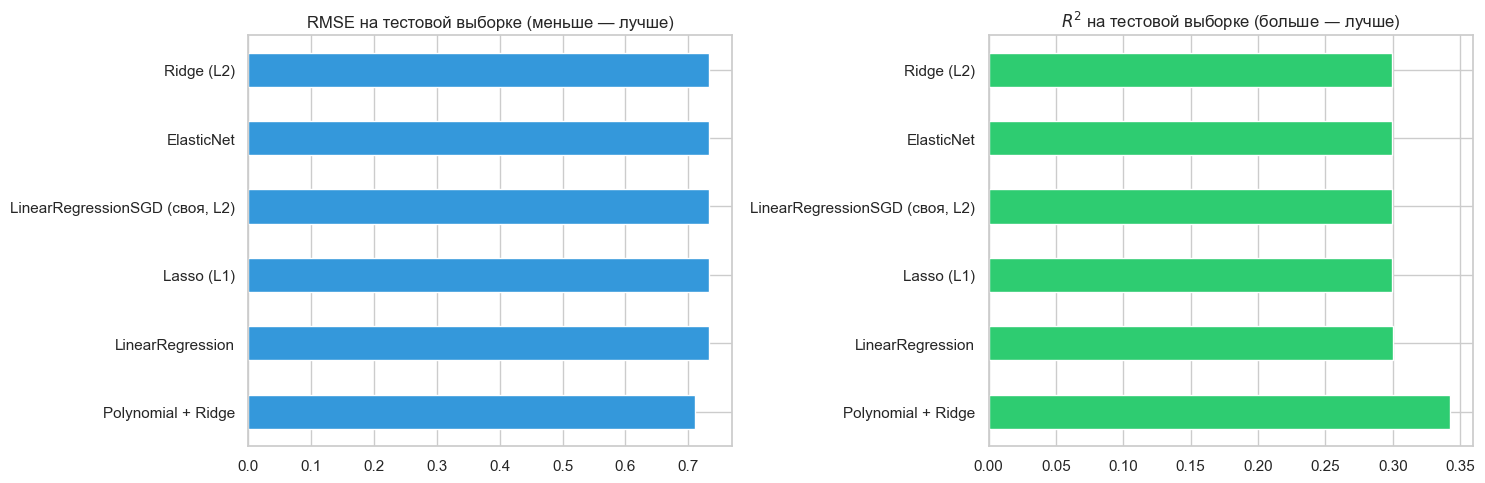

In [16]:
summary = pd.DataFrame(results).T.sort_values('RMSE')
display(summary.style.format('{:.4f}').highlight_min(subset=['MSE', 'RMSE', 'MAE', 'MAPE'], color='#c8e6c9')
        .highlight_max(subset=['R2'], color='#c8e6c9'))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
summary['RMSE'].plot(kind='barh', ax=axes[0], color='#3498db')
axes[0].set_title('RMSE на тестовой выборке (меньше — лучше)')
summary['R2'].plot(kind='barh', ax=axes[1], color='#2ecc71')
axes[1].set_title('$R^2$ на тестовой выборке (больше — лучше)')
plt.tight_layout()
plt.show()

## Выводы
1. **Сравнение линейных моделей.** На базовом наборе из 12 признаков обычная линейная регрессия (МНК), Lasso ($L_1$), Ridge ($L_2$) и ElasticNet показывают практически идентичное качество на тестовой выборке ($MSE \approx 0.538$, $RMSE \approx 0.733$, $MAE \approx 0.571$, $R^2 \approx 0.300$). Небольшие оптимальные значения коэффициентов регуляризации говорят о том, что при $N = 4872$ и 12 признаках классический МНК ещё не склонен к сильному переобучению, однако $L_2$-регуляризация стабилизирует веса коррелирующих признаков (`density` и `residual sugar`).
2. **Полиномиальные признаки + регуляризация.** Добавление полиномиальных признаков степени 2 в связке с $L_2$-регуляризацией (`PolynomialFeatures(degree=2)` + `Ridge(alpha=306.5)`) даёт **лучший результат среди всех исследованных моделей**: $MSE = 0.5051$, $RMSE = 0.7107$, $MAE = 0.5575$, $R^2 = 0.3423$ (прирост $R^2$ более чем на 4 п.п.). Это подтверждает нелинейный характер зависимости качества вина от взаимодействий физико-химических параметров. В то же время полином степени 3 без регуляризации сильно переобучается ($MSE_{train} = 0.3988$, но $MSE_{test} = 0.6275$), поэтому подбор гиперпараметров обязан проводиться на кросс-валидации.
3. **Собственная реализация `LinearRegressionSGD`.** Реализованный вручную регрессор с мини-батчевым стохастическим градиентным спуском и $L_2$-штрафом сходится за ~100 эпох и достигает $MSE = 0.5379$, $R^2 = 0.2996$, а найденные им веса отличаются от аналитического решения `sklearn.linear_model.Ridge` менее чем на $0.003$.
4. **Верификация метрик.** Собственные реализации $MSE$, $RMSE$, $MAE$, $MAPE$ и $R^2$ полностью совпали с функциями `scikit-learn` на всех 6 моделях.